In [1]:
import pandas as pd

from gaia_variable_stars import plots
from gaia_variable_stars.config import CLASSES, CLEAN_FILE, LABELED_FILE
from gaia_variable_stars.dataset import clean

pd.set_option("display.max_columns", 50)

The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.


In [2]:
data = pd.read_csv(LABELED_FILE, low_memory=False)
data.shape

(88616, 31)

In [3]:
data.isna().mean().mul(100).round(1).loc[lambda s: s > 0]

g_transit_time                1.5
g_transit_flux                1.5
g_transit_flux_error          1.5
g_transit_flux_over_error     1.5
g_transit_mag                 1.5
bp_obs_time                  14.6
bp_flux                      14.6
bp_flux_error                14.6
bp_flux_over_error           14.6
bp_mag                       14.6
rp_obs_time                  12.0
rp_flux                      12.0
rp_flux_error                12.0
rp_flux_over_error           12.0
rp_mag                       12.0
bp_mean_magnitude             1.7
rp_mean_magnitude             1.7
bp_rp_color                   1.7
dtype: float64

In [4]:
tidy = clean(data)

print("Epochs:", data.shape[0], "->", tidy.shape[0])

Epochs: 88616 -> 84278


In [5]:
1 - tidy.groupby("class_name").size() / data.groupby("class_name").size()

class_name
Cepheid                 0.059256
Eclipsing Binary        0.051008
Long-Period Variable    0.036556
RR Lyrae                0.047267
dtype: float64

In [6]:
CLEAN_FILE.parent.mkdir(parents=True, exist_ok=True)
tidy.to_csv(CLEAN_FILE, index=False)

In [7]:
stars = (
    tidy.groupby(["source_id", "class_name"])
    .agg(
        points=("g_transit_mag", "size"),
        swing=("g_transit_mag", lambda s: s.max() - s.min()),
        span=("g_transit_time", lambda s: s.max() - s.min()),
        mag=("g_mean_magnitude", "first"),
        color=("bp_rp_color", "first"),
    )
    .reset_index()
)

stars["class_name"].value_counts().reindex(CLASSES)

class_name
RR Lyrae                500
Cepheid                 500
Eclipsing Binary        500
Long-Period Variable    500
Name: count, dtype: int64

In [8]:
stars.groupby("class_name")[["points", "swing", "span"]].describe().T

class_name        Cepheid  Eclipsing Binary  Long-Period Variable     RR Lyrae
points count   500.000000        500.000000            500.000000   500.000000
       mean     45.786000         43.572000             41.062000    38.136000
       std      19.951951         18.404409             16.804492    17.451838
       min      21.000000         16.000000             17.000000    12.000000
       25%      36.000000         30.000000             28.000000    27.000000
       50%      43.000000         42.000000             39.000000    36.000000
       75%      48.000000         52.000000             49.000000    45.000000
       max     245.000000        170.000000            133.000000   200.000000
swing  count   500.000000        500.000000            500.000000   500.000000
       mean      0.551009          0.415742              0.436330     0.665346
       std       0.283963          0.226414              0.545036     0.254819
       min       0.057972          0.050013              0.108963     0.151666
       25%       0.334589          0.260808              0.184101     0.433869
       50%       0.502041          0.366296              0.261664     0.631724
       75%       0.729495          0.530647              0.415001     0.856382
       max       2.970491          1.982264              3.386845     1.561599
span   count   500.000000        500.000000            500.000000   500.000000
       mean    960.429570        946.881163            943.974209   933.248716
       std      35.224001         41.751348             38.815650    60.657267
       min     799.557419        581.390868            719.669691   611.124380
       25%     945.974035        922.441191            925.252800   917.528648
       50%     971.357616        956.577856            961.274852   944.700803
       75%     980.905813        971.513728            966.564533   971.260441
       max    1019.164550       1020.238839           1020.907631  1037.653208

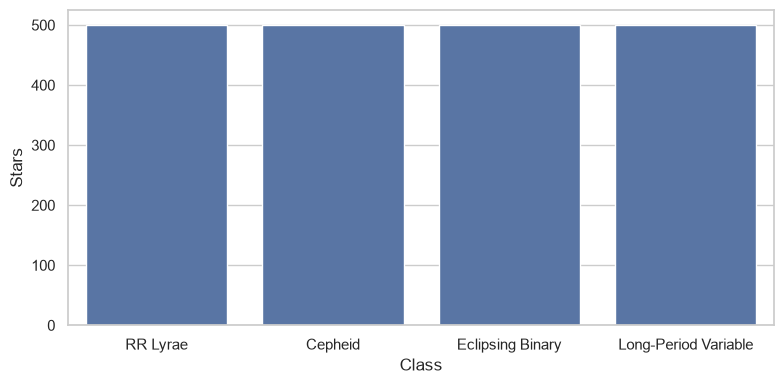

In [9]:
plots.counts(stars)

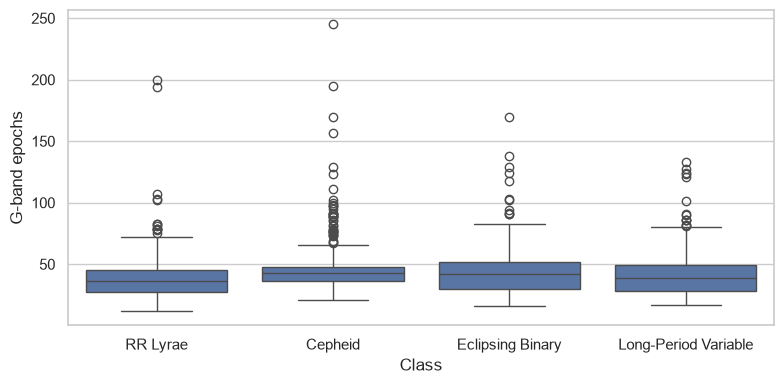

In [10]:
plots.points(stars)

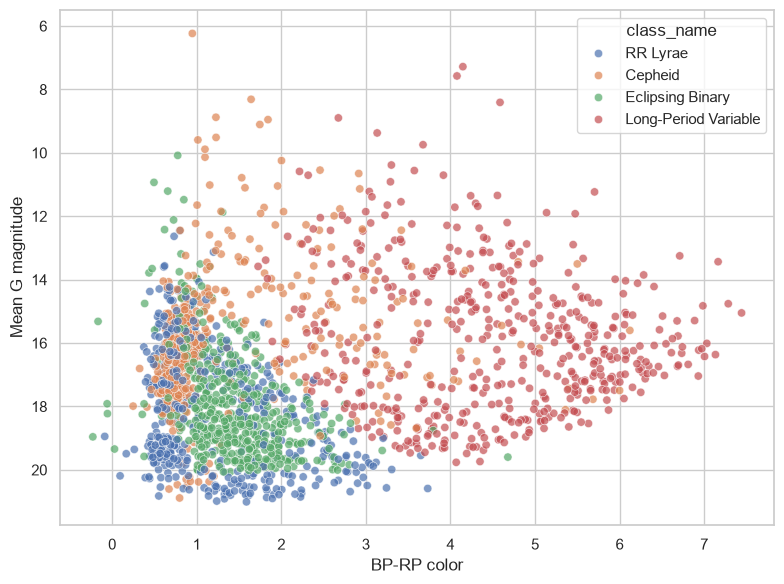

In [11]:
plots.cmd(stars)

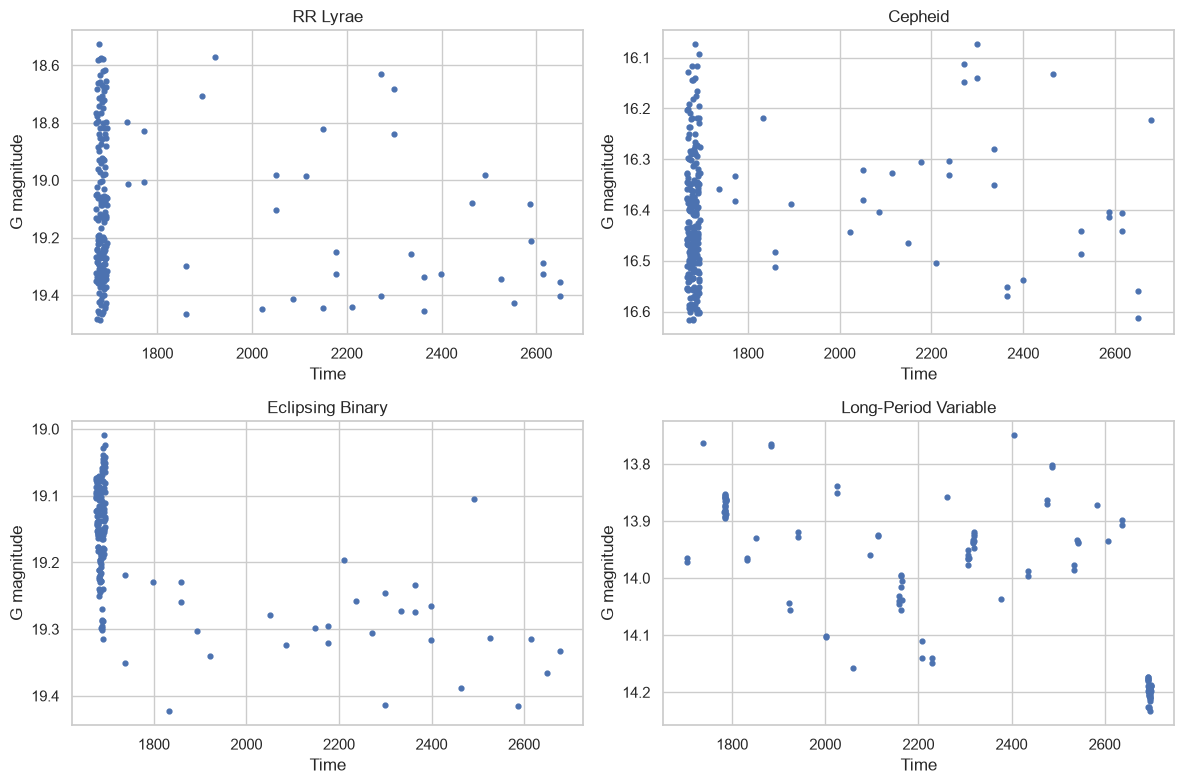

In [12]:
plots.curves(tidy)